# EduPulse: Product-Led Growth & Churn Analytics
# Комплексный аудит юнит-экономики, каналов привлечения и поиск Aha-момента для EdTech-платформы


## Бизнес-контекст и архитектура решения
ЭдуПалс (EduPulse) - это образовательная платформа, которая зарабатывает на подписках. Сейчас у проекта есть четкий запрос на масштабирование, но заливать деньги в маркетинг бездумно нельзя. Моя цель в этом исследовании - разобраться в причинах оттока и найти точки кратного роста. Я взял данные по поведению 1200 юзеров и решил посмотреть, что реально заставляет их оставаться или уходить. 

Я проведу аудит рекламных каналов, чтобы понять, откуда приходят самые лояльные клиенты. Затем мы найдем продуктовый Aha-момент - то самое ключевое действие, после которого пользователь с максимальной вероятностью закрепляется в приложении. В финале я разберу технические барьеры, провоцирующие отток, и соберу результаты на едином дашборде.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px
edupulse_df_start = pd.read_csv('edupulse_users.csv') 

In [3]:
edupulse_df_clean = (
    edupulse_df_start.query('age > 16 and age < 80 and total_hours >= 0')
    .assign(reg_date = lambda x: pd.to_datetime(x['reg_date']),
            last_login = lambda x: pd.to_datetime(x['last_login']),
            source = lambda x: x['source'].str.strip().str.lower())
    .dropna(subset = ['nps_score'])
)

## Эффективность каналов привлечения (Acquisition Channels)
Начинаем с оценки трафика. Нужно понять, откуда приходят самые горячие и платящие клиенты, чтобы не сливать рекламный бюджет в пустоту. Органика и Telegram ожидаемо показывают отличную конверсию в покупку. Остальные каналы пока просто нагоняют бесплатных юзеров, которые редко доходят до реальной оплаты.

In [5]:
df_ads = (
    edupulse_df_clean.groupby('source')
    .agg(paid_users = ('plan', lambda x: x.isin(['basic','pro']).sum()),
        free_users = ('plan', lambda x: (x == 'free').sum()))
    .sort_values('paid_users', ascending = False)
)
df_ads

,paid_users,free_users
source,,
telegram,187,45
organic,181,87
referral,169,32
vk_ads,118,113
yandex_direct,110,84
email,93,17


Если посмотреть на демографию, вырисовывается занятная картина. Наша основная масса - это семнадцатилетние ребята, которые только-только пробуют себя в IT. Зато аудитория постарше, хоть ее и количественно меньше, платит гораздо охотнее и стабильно выбирает тарифы Basic и Pro.

In [9]:
mean_rev = (
    edupulse_df_clean.groupby('source',as_index = False)
    .agg(mean_revenue = ('revenue','mean'))
    .round({'mean_revenue':2})
    .sort_values('mean_revenue',ascending = False)
)
mean_rev

,source,mean_revenue
0,email,9021.55
2,referral,8221.79
1,organic,6334.59
3,telegram,6001.81
5,yandex_direct,4726.08
4,vk_ads,4143.12


## Факторный анализ оттока (Churn Rate)
Сейчас мы теряем около 35 процентов аудитории, и это больно бьет по юнит-экономике. Я решил копнуть глубже и разбить отток по каналам и тарифам. Результат оказался предсказуемым, но показательным: реклама в VK Ads вообще не окупается. Люди оттуда приходят и быстро уходят. А вот Telegram снова доказывает свою ценность - оттуда идет самая удерживаемая аудитория.

In [10]:
edupulse_df_clean['is_churned'].value_counts(normalize = True).mul(100).round(2)

is_churned
0    64.24
1    35.76
Name: proportion, dtype: float64

In [11]:
churn_rate_source = (
    edupulse_df_clean.groupby('source', as_index = False)
    .agg(mean_churn = ('is_churned','mean'))
    .round({'mean_churn':2})
    .sort_values('mean_churn',ascending = False)
)
churn_rate_source

,source,mean_churn
4,vk_ads,0.55
1,organic,0.37
5,yandex_direct,0.36
0,email,0.32
3,telegram,0.27
2,referral,0.23


In [12]:
churn_rate_plan = (
    edupulse_df_clean.groupby('plan', as_index = False)
    .agg(mean_churn = ('is_churned','mean'))
    .round({'mean_churn':2})
    .sort_values('mean_churn',ascending = False)
)
churn_rate_plan

,plan,mean_churn
1,free,0.58
0,basic,0.35
2,pro,0.14


## Продуктовые метрики и поиск Aha-момента
Мне было важно найти тот самый триггер, после которого пользователь решает остаться с нами надолго. Оказалось, что наш Aha-момент - это три завершенных курса. Как только человек проходит эту отметку, вероятность его ухода падает почти до нуля.

Заодно я посмотрел на корреляцию оттока с обращениями в саппорт. Тут все жестко: баги убивают лояльность. Чем больше тикетов пишет юзер, тем быстрее он отменяет подписку. Это прямой сигнал для разработки - нужно срочно чинить технические долги.

In [ ]:
edupulse_df_clean.corr(numeric_only = True).round(2)

,user_id,age,courses_started,courses_completed,total_hours,support_tickets,nps_score,revenue,is_churned
user_id,1.00,0.02,0.01,0.01,0.01,0.02,-0.01,-0.01,-0.01
age,0.02,1.00,-0.01,0.00,0.00,-0.03,0.03,-0.04,-0.02
courses_started,0.01,-0.01,1.00,0.93,0.94,-0.14,0.15,0.27,-0.23
courses_completed,0.01,0.00,0.93,1.00,0.95,-0.14,0.16,0.33,-0.26
total_hours,0.01,0.00,0.94,0.95,1.00,-0.14,0.16,0.34,-0.24
support_tickets,0.02,-0.03,-0.14,-0.14,-0.14,1.00,-0.35,-0.12,0.49
nps_score,-0.01,0.03,0.15,0.16,0.16,-0.35,1.00,0.19,-0.66
revenue,-0.01,-0.04,0.27,0.33,0.34,-0.12,0.19,1.00,-0.24
is_churned,-0.01,-0.02,-0.23,-0.26,-0.24,0.49,-0.66,-0.24,1.00


In [15]:
remain_stat = (
    edupulse_df_clean.query('courses_completed > 2')
    ['is_churned']
    .value_counts(normalize = True)
)
remain_stat

is_churned
0    0.900826
1    0.099174
Name: proportion, dtype: float64

In [16]:
edupulse_df_clean['courses_completed'].describe()

count    1236.000000
mean        1.445793
std         2.585442
min         0.000000
25%         0.000000
50%         0.000000
75%         2.000000
max        21.000000
Name: courses_completed, dtype: float64

## Когортный анализ и LTV
Я собрал когорты по дате регистрации и возрасту, чтобы посмотреть на LTV в динамике. Ядро платформы держится отлично. При этом старшая аудитория ожидаемо приносит больше денег на длинной дистанции. Они редко бросают учебу на полпути и стабильно продлевают подписки из месяца в месяц.

In [17]:
edupulse_df_clean['reg_date'].describe()

count                          1236
mean     2025-10-18 18:09:19.223301
min             2025-01-01 00:00:00
25%             2025-05-17 00:00:00
50%             2025-10-12 00:00:00
75%             2026-03-21 06:00:00
max             2026-08-30 00:00:00
Name: reg_date, dtype: object

In [18]:
cohort_df = (
    edupulse_df_clean.assign(
        date_cohort = lambda x: pd.cut(
            x['reg_date'],
            bins = [pd.to_datetime('2025-01-01 00:00:00'), pd.to_datetime('2025-05-17 00:00:00'), pd.to_datetime('2025-10-12 00:00:00'), pd.to_datetime('2026-03-21 06:00:000'), pd.to_datetime('2026-08-30 00:00:00')],
            labels = ['0','1','2','3']
        )
    ).dropna(subset = ['date_cohort'])
)
cohort_df['date_cohort'] = cohort_df['date_cohort'].astype(int)

In [20]:
cohort_rev = (
    cohort_df.groupby('date_cohort', as_index = False)
    .agg(mean_rev = ('revenue','mean'))
    .round({'mean_rev':0})
)
cohort_rev

,date_cohort,mean_rev
0,0,9986.0
1,1,7773.0
2,2,4839.0
3,3,2030.0


In [49]:
retention_df = (
    cohort_df.assign(day_diff = lambda x: x['last_login'] - x['reg_date'])
)
retention_df.head()

,user_id,reg_date,city,age,gender,source,plan,courses_started,courses_completed,total_hours,last_login,support_tickets,nps_score,revenue,is_churned,device,date_cohort,cohort,day_diff
1,77,2025-02-22,Санкт-Петербург,39,F,email,pro,0,0,0.5,2026-09-19,0,8.0,32370.0,0,desktop,0,2025-02,574 days
2,1010,2025-02-23,Екатеринбург,39,M,vk_ads,basic,0,0,12.3,2026-05-01,6,4.0,17820.0,1,desktop,0,2025-02,432 days
3,1404,2026-05-04,Ростов-на-Дону,20,F,email,basic,0,0,0.0,2026-09-20,1,7.0,2970.0,0,mobile,3,2026-05,139 days
4,847,2025-02-11,Екатеринбург,34,F,vk_ads,pro,4,1,76.4,2026-09-23,0,7.0,22410.0,0,desktop,0,2025-02,589 days
5,1099,2025-01-29,Москва,25,F,organic,basic,1,0,9.5,2026-07-02,6,2.0,1980.0,1,mobile,0,2025-01,519 days


In [23]:
courses_cohorts2 = (
    cohort_df.assign(
        courses_comp_cohort = lambda x:
            pd.cut(
                x['courses_completed'],
                bins = [-1,0,2,10,15,22],
                labels = ['0','1-2','3-10','11-15','16-21']
            )
    ).groupby('courses_comp_cohort',as_index = False)
    .agg(churn_mean = ('is_churned','mean'))
    .assign(churn_prc = lambda x: (x['churn_mean']*100).round())
    .sort_values('churn_prc',ascending = False)
)
courses_cohorts2

,courses_comp_cohort,churn_mean,churn_prc
0,0,0.497758,50.0
1,1-2,0.256966,26.0
4,16-21,0.200000,20.0
2,3-10,0.096330,10.0
3,11-15,0.055556,6.0


In [24]:
cohort_df['cohort'] = cohort_df['reg_date'].dt.to_period('M')
cohort_df
cohort_grouped = (
    cohort_df.groupby('cohort',as_index = False)
    .agg(mean_rev = ('revenue','mean'))
    .round({'mean_rev':0})
    .astype({'mean_rev':int})
)


## Итоговый дашборд
Всю ключевую аналитику я собрал в один общий визуальный дашборд. Он помогает стейкхолдерам быстро оценить здоровье продукта, понять демографию и отследить динамику оттока без погружения в сырые таблицы.

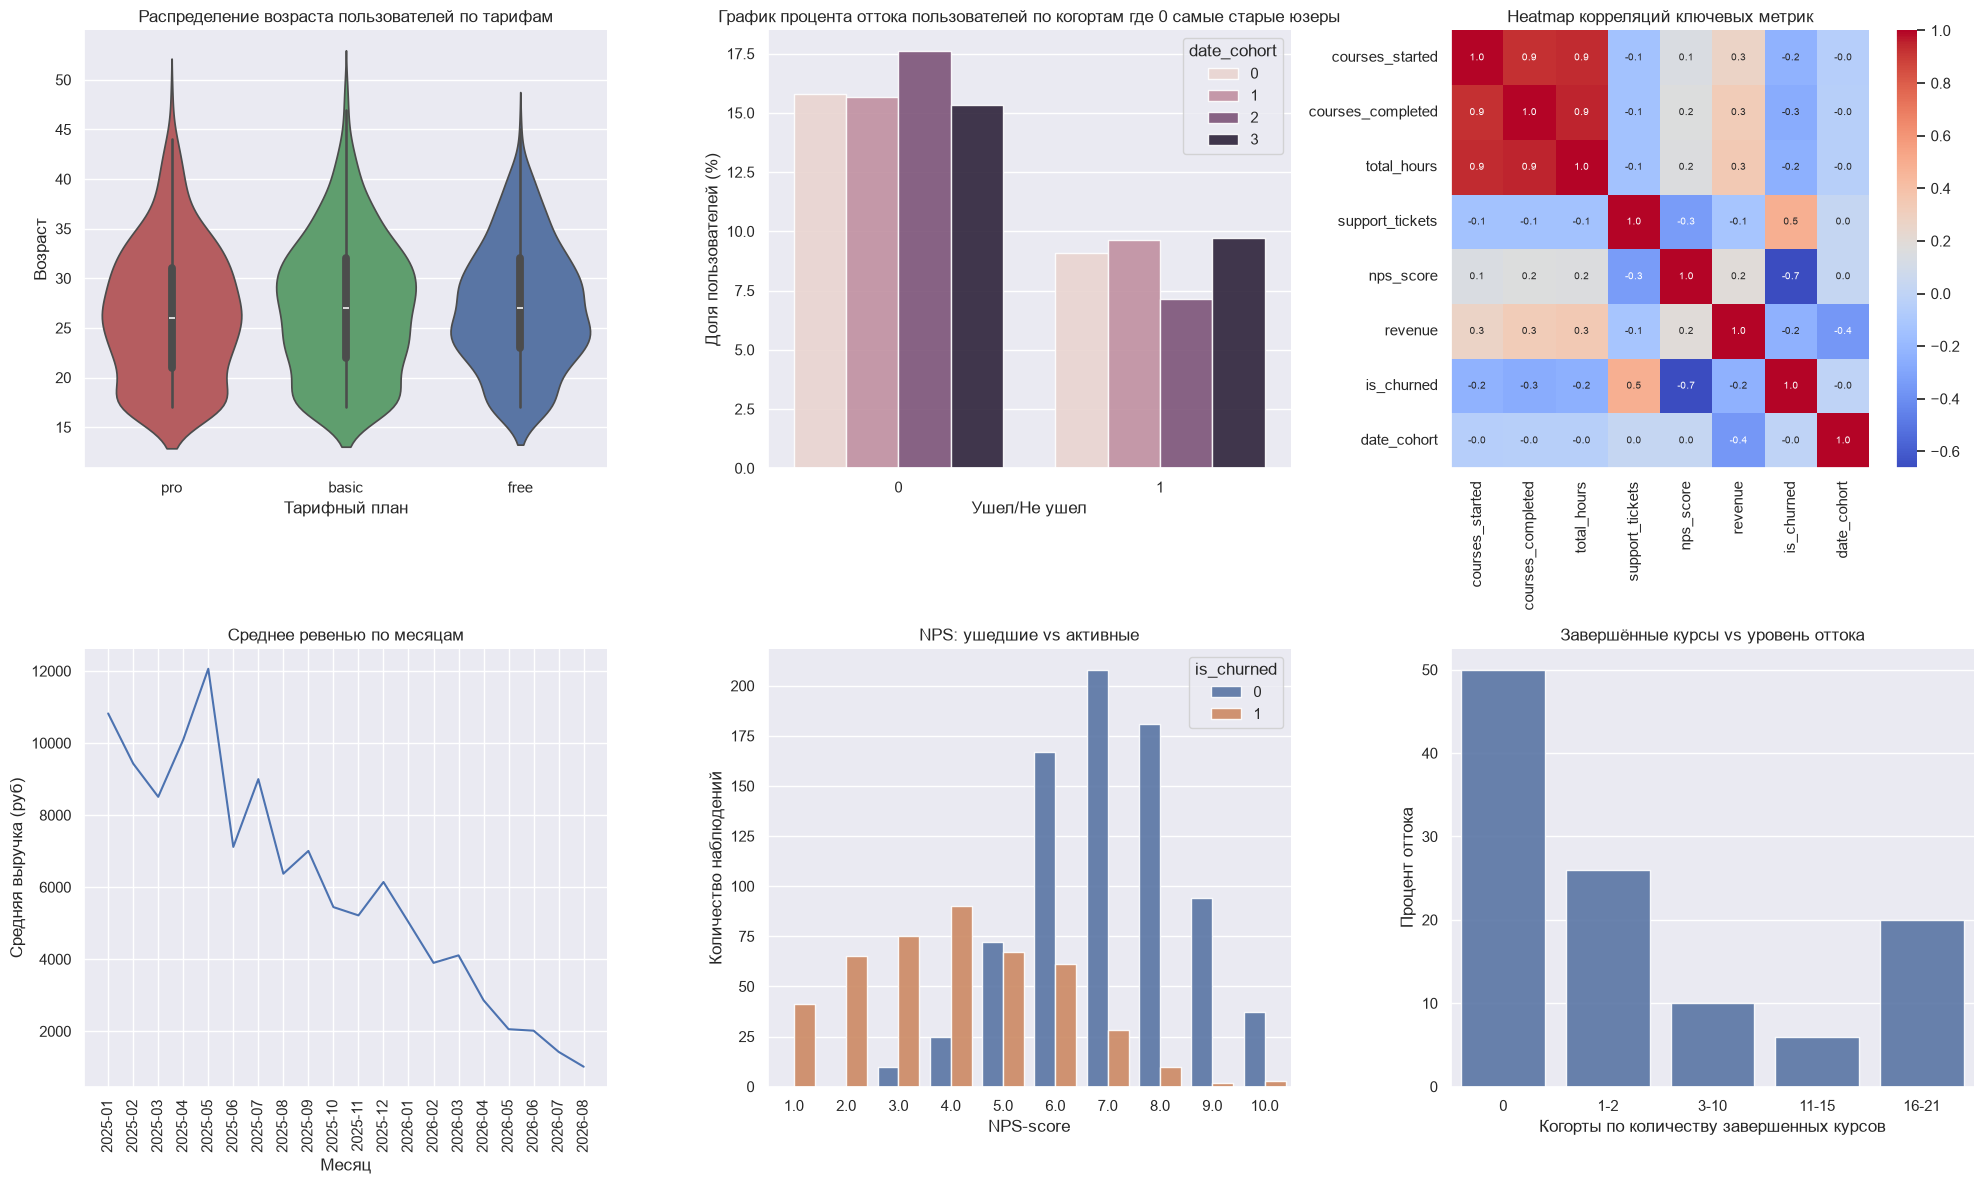

In [47]:
fig, axes = plt.subplots(nrows = 2, ncols = 3, figsize = (20,12))
axes = axes.flatten()

plan_plot = sns.violinplot(data = edupulse_df_clean, x = 'plan', y = 'age', palette = ['r','g','b'] ,hue = 'plan' , legend =False,ax = axes[0])
plan_plot.set_title('Распределение возраста пользователей по тарифам')
plan_plot.set_xlabel('Тарифный план')
plan_plot.set_ylabel('Возраст')

churn_plot2 = sns.countplot(data = cohort_df, x = 'is_churned', hue = 'date_cohort', stat = 'percent',alpha = 0.9, ax = axes[1])
churn_plot2.set_title('График процента оттока пользователей по когортам где 0 самые старые юзеры')
churn_plot2.set_xlabel('Ушел/Не ушел')
churn_plot2.set_ylabel('Доля пользователей (%)')

heatmap_df = cohort_df.drop(columns = ['user_id','city','reg_date','plan','gender','device','source','last_login','age','cohort'])
corr_plot = sns.heatmap(data = heatmap_df.corr(), annot=True, cmap="coolwarm",annot_kws={'size': 7},fmt = '.1f', ax = axes[2])
corr_plot.set_title('Heatmap корреляций ключевых метрик')

cohort_grouped['cohort'] = cohort_grouped['cohort'].astype(str)
cohort_mean_rev = sns.lineplot(data = cohort_grouped, x = 'cohort', y = 'mean_rev',ax = axes[3])
axes[3].tick_params(axis='x', rotation=90)
cohort_mean_rev.set_title('Среднее ревенью по месяцам')
cohort_mean_rev.set_xlabel('Месяц')
cohort_mean_rev.set_ylabel('Средняя выручка (руб)')
sns.despine()


nps_churn_plot = sns.countplot(data = edupulse_df_clean, x = 'nps_score', hue = 'is_churned',alpha = 0.9, ax = axes[4])
nps_churn_plot.set_title('NPS: ушедшие vs активные')
nps_churn_plot.set_xlabel('NPS-score')
nps_churn_plot.set_ylabel('Количество наблюдений')


course_comp_churn_plot = sns.barplot(data = courses_cohorts2, x ='courses_comp_cohort',y = 'churn_prc',alpha = 0.9,ax = axes[5])
course_comp_churn_plot.set_title('Завершённые курсы vs уровень оттока')
course_comp_churn_plot.set_xlabel('Когорты по количеству завершенных курсов')
course_comp_churn_plot.set_ylabel('Процент оттока')


plt.tight_layout()
plt.savefig('eda_dashboard.png', dpi=300, bbox_inches='tight', facecolor='white')

## Стратегические выводы и план действий
Главная проблема оттока сейчас кроется в технической части и онбординге. Юзеры не прощают багов, а те, у кого падает NPS, уходят молча. Нам нужно настроить триггерные письма и давать бонусы тем, кто завис и сомневается.

По маркетингу решение очевидное - пора резать бюджеты на VK Ads и переливать эти деньги в Telegram. VK сейчас работает в минус. Продуктовой команде стоит сфокусироваться на том, чтобы за ручку доводить каждого новичка до отметки в три завершенных курса. Ну и не забываем про 17-летних студентов - это наша самая большая аудитория, и интерфейс должен быть заточен в первую очередь под их сценарии.